<a href="https://colab.research.google.com/github/MaximSS1309/ML_SEREDOVSKIJ_MAXM/blob/main/%D0%9B%D0%A04_%D0%9C%D0%9D_%D1%81%D0%B5%D1%80%D0%B5%D0%B4%D0%BE%D0%B2%D1%81%D1%8C%D0%BA%D0%B8%D0%B9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [4]:
import pandas as pd
from google.colab import files

print("Будь ласка, натисніть кнопку нижче та оберіть файл 'CarPrice_Assignment.csv':")
uploaded = files.upload()

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print("\n--- Кількість об'єктів і ознак ---")
print(f"Кількість об'єктів (рядків): {df.shape[0]}")
print(f"Кількість ознак (стовпців): {df.shape[1]}")
print(f"Загальна форма (shape): {df.shape}\n")

print("--- Назви стовпців ---")
print(df.columns.tolist())
print()

print("--- Типи даних у стовпцях ---")
print(df.dtypes)
print()

target_variable = "price"
print(f"--- Цільова змінна ---")
print(f"Цільова змінна: '{target_variable}' (Ціна автомобіля)\n")

print("--- Основні статистичні характеристики (для числових ознак) ---")
display(df.describe())

print("\n--- Статистика для категоріальних ознак ---")
display(df.describe(include=["O"]))

Будь ласка, натисніть кнопку нижче та оберіть файл 'CarPrice_Assignment.csv':


Saving CarPrice_Assignment.csv to CarPrice_Assignment.csv

--- Кількість об'єктів і ознак ---
Кількість об'єктів (рядків): 205
Кількість ознак (стовпців): 26
Загальна форма (shape): (205, 26)

--- Назви стовпців ---
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

--- Типи даних у стовпцях ---
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype      

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000



--- Статистика для категоріальних ознак ---


,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,enginetype,cylindernumber,fuelsystem
count,205,205,205,205,205,205,205,205,205,205
unique,147,2,2,2,5,3,2,7,7,8
top,peugeot 504,gas,std,four,sedan,fwd,front,ohc,four,mpfi
freq,6,185,168,115,96,120,202,148,159,94


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [6]:

print("--- 1. Наявність пропущених значень ---")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0]) if missing_values.sum() > 0 else print("Пропущені значення відсутні у датасеті.")

print("\n--- 2. Наявність повних дублікатів (без урахування car_ID) ---")

df_without_id = df.drop(columns=['car_ID'])
duplicates_count = df_without_id.duplicated().sum()
print(f"Кількість повних дублікатів за змістовими ознаками: {duplicates_count}")

print("\n--- 3. Кількість унікальних значень в ознаках ---")
print(df.nunique())

--- 1. Наявність пропущених значень ---
Пропущені значення відсутні у датасеті.

--- 2. Наявність повних дублікатів (без урахування car_ID) ---
Кількість повних дублікатів за змістовими ознаками: 0

--- 3. Кількість унікальних значень в ознаках ---
car_ID              205
symboling             6
CarName             147
fueltype              2
aspiration            2
doornumber            2
carbody               5
drivewheel            3
enginelocation        2
wheelbase            53
carlength            75
carwidth             44
carheight            49
curbweight          171
enginetype            7
cylindernumber        7
enginesize           44
fuelsystem            8
boreratio            38
stroke               37
compressionratio     32
horsepower           59
peakrpm              23
citympg              29
highwaympg           30
price               189
dtype: int64


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [7]:

car_ids = df['car_ID'].copy()

if 'car_ID' in df.columns:
    df = df.drop(columns=['car_ID'])
    print("Стоплєць 'car_ID' успішно збережено окремо та видалено з основного датасету (df).")
else:
    print("Стоплєць 'car_ID' вже був видалений раніше.")

print(f"\nКількість ознак після видалення car_ID: {df.shape[1]}")

Стоплєць 'car_ID' успішно збережено окремо та видалено з основного датасету (df).

Кількість ознак після видалення car_ID: 25


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


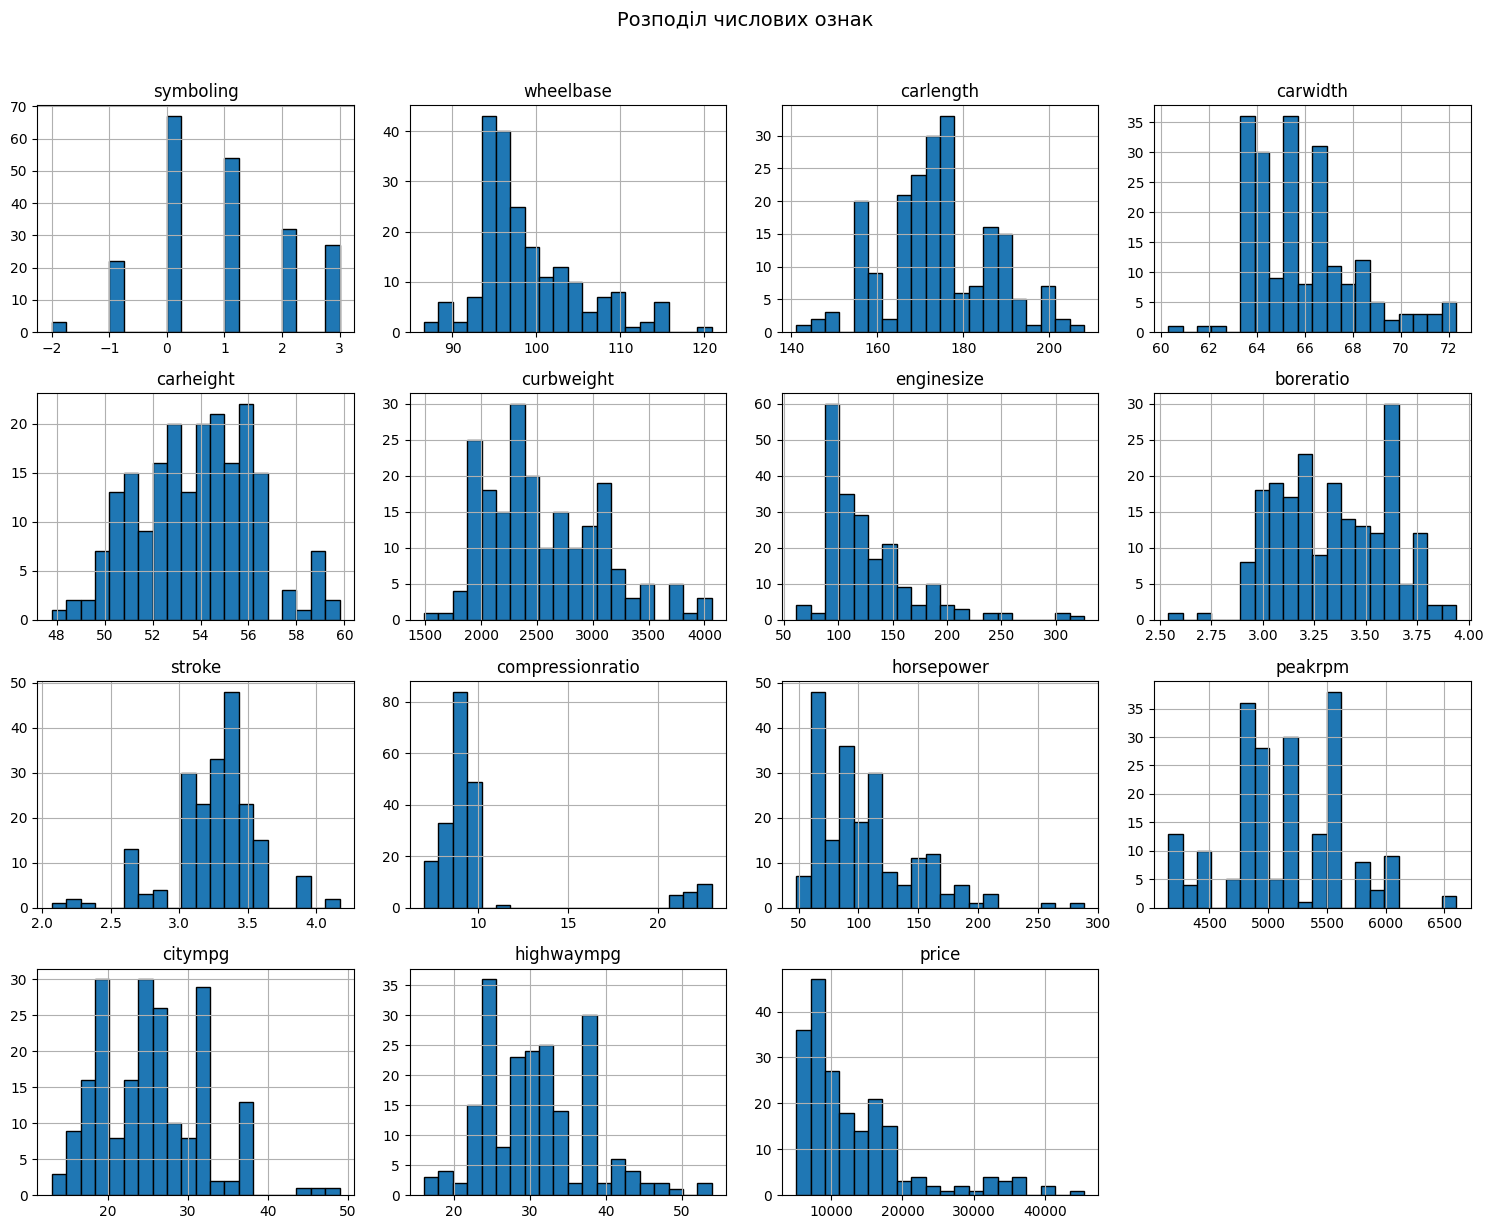

Коефіцієнти асиметрії числових ознак:
compressionratio    2.610862
enginesize          1.947655
price               1.777678
horsepower          1.405310
wheelbase           1.050214
carwidth            0.904003
curbweight          0.681398
citympg             0.663704
highwaympg          0.539997
symboling           0.211072
carlength           0.155954
peakrpm             0.075159
carheight           0.063123
boreratio           0.020156
stroke             -0.689705
dtype: float64

Ознаки з найбільшою асиметрією (за модулем):
compressionratio    2.610862
enginesize          1.947655
price               1.777678
dtype: float64


In [8]:
import matplotlib.pyplot as plt
import seaborn as sns


numeric_features = df.select_dtypes(include=['int64', 'float64']).columns

df[numeric_features].hist(bins=20, figsize=(15, 12), edgecolor='black')
plt.suptitle('Розподіл числових ознак', y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

skewness = df[numeric_features].skew().sort_values(ascending=False)
print("Коефіцієнти асиметрії числових ознак:")
print(skewness)

print("\nОзнаки з найбільшою асиметрією (за модулем):")
print(skewness.abs().sort_values(ascending=False).head(3))

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [9]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['price'])
y = df['price']

X_train, X_test, y_train, y_test, train_ids, test_ids = train_test_split(
    X, y, car_ids, test_size=0.2, random_state=42
)

print(f"Розмір навчальної вибірки (train): {X_train.shape[0]} об'єктів")
print(f"Розмір тестової вибірки (test): {X_test.shape[0]} об'єктів")
print(f"Кількість збережених car_ID у train: {len(train_ids)}")
print(f"Кількість збережених car_ID у test: {len(test_ids)}")

Розмір навчальної вибірки (train): 164 об'єктів
Розмір тестової вибірки (test): 41 об'єктів
Кількість збережених car_ID у train: 164
Кількість збережених car_ID у test: 41


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [10]:
import numpy as np

# Вибираємо лише неперервні числові ознаки у train (цільову змінну price не чіпаємо)
numeric_train = X_train.select_dtypes(include=['int64', 'float64'])

outliers_info = {}
X_train_clamped = X_train.copy()
X_test_clamped = X_test.copy()

for col in numeric_train.columns:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Визначаємо кількість викидів у train
    outliers_count = ((X_train[col] < lower_bound) | (X_train[col] > upper_bound)).sum()
    outliers_info[col] = outliers_count

    # Обмежуємо крайні значення (кліпінг) за межами train для train та test
    X_train_clamped[col] = np.clip(X_train[col], lower_bound, upper_bound)
    X_test_clamped[col] = np.clip(X_test[col], lower_bound, upper_bound)

print("Кількість потенційних викидів для кожної ознаки (за IQR):")
for col, count in outliers_info.items():
    print(f"{col}: {count}")
#оскільки набір даних невеликий, повне видалення рядків з викидами призведе до втрати цінної інформації. Тому застосовано обмеження крайніх значень межами, розрахованими виключно за навчальною вибіркою.

Кількість потенційних викидів для кожної ознаки (за IQR):
symboling: 0
wheelbase: 6
carlength: 0
carwidth: 10
carheight: 0
curbweight: 0
enginesize: 7
boreratio: 1
stroke: 16
compressionratio: 20
horsepower: 7
peakrpm: 2
citympg: 0
highwaympg: 1

Обумовлення: оскільки набір даних невеликий, повне видалення рядків з викидами призведе до втрати цінної інформації. Тому застосовано обмеження (кліпінг) крайніх значень межами, розрахованими виключно за навчальною вибіркою.


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


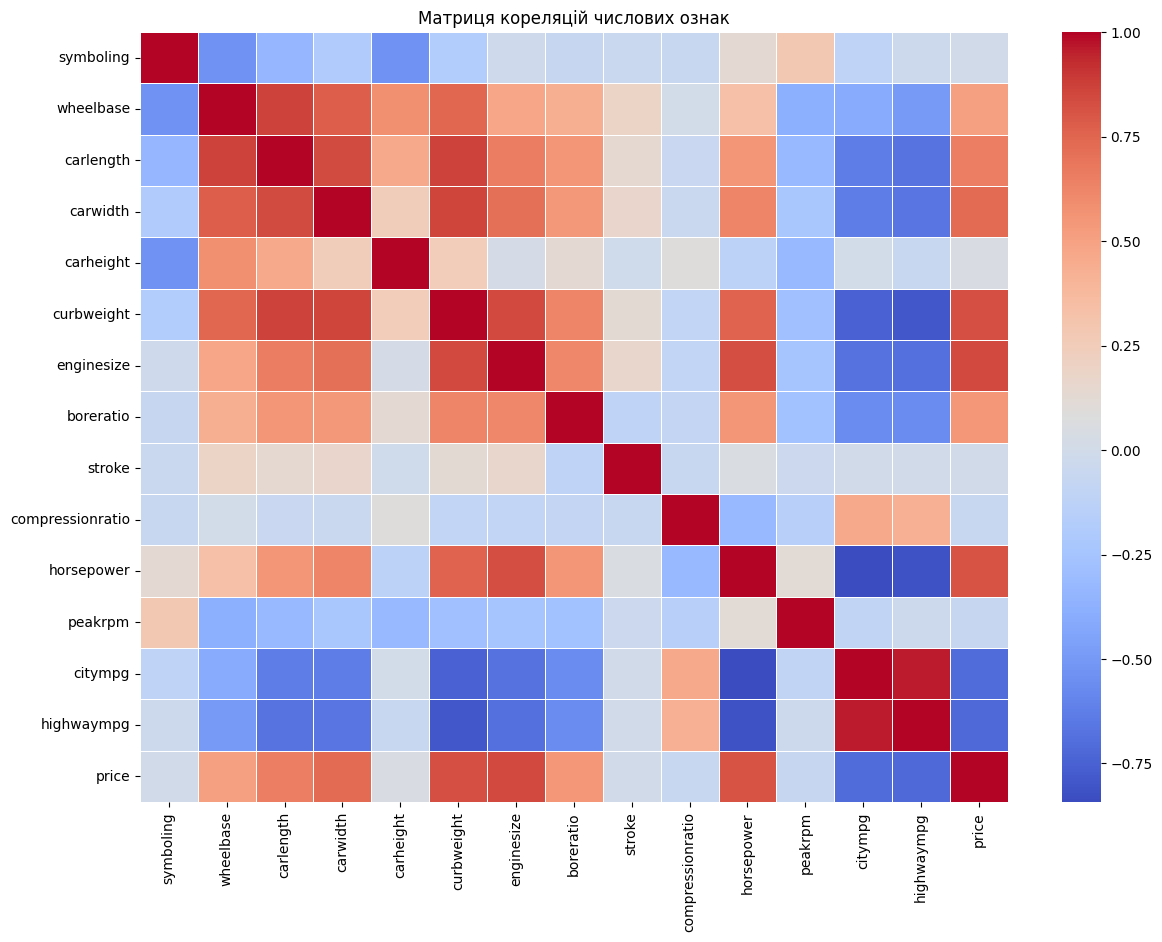

Пари ознак із сильною кореляцією (|r| > 0.85):
carlength та wheelbase: коефіцієнт = 0.87
curbweight та carlength: коефіцієнт = 0.87
curbweight та carwidth: коефіцієнт = 0.86
highwaympg та citympg: коефіцієнт = 0.96

Список ознак, що видаляються через сильну мультиколінеарність:
['carlength', 'citympg', 'wheelbase', 'carwidth']

Кількість ознак у train після відбору: 20
Кількість ознак у test після відбору: 20


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_train_for_corr = X_train_clamped.select_dtypes(include=['int64', 'float64']).copy()
numeric_train_for_corr['price'] = y_train.values

# 1. Побудова матриці кореляцій числових ознак
plt.figure(figsize=(14, 10))
corr_matrix = numeric_train_for_corr.corr()
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Матриця кореляцій числових ознак')
plt.show()

# 2. Знаходження пар ознак із сильною кореляцією (|r| > 0.85)
high_corr_pairs = []
columns = numeric_train_for_corr.columns.drop('price')

for i in range(len(columns)):
    for j in range(i):
        if abs(corr_matrix.loc[columns[i], columns[j]]) > 0.85:
            high_corr_pairs.append((columns[i], columns[j], corr_matrix.loc[columns[i], columns[j]]))

print("Пари ознак із сильною кореляцією (|r| > 0.85):")
for pair in high_corr_pairs:
    print(f"{pair[0]} та {pair[1]}: коефіцієнт = {pair[2]:.2f}")

# 3. Вибір ознак для видалення на основі зв'язку з цільовою змінною price
features_to_drop = set()
for col1, col2, _ in high_corr_pairs:
    corr_1 = abs(corr_matrix.loc[col1, 'price'])
    corr_2 = abs(corr_matrix.loc[col2, 'price'])

    if corr_1 < corr_2:
        features_to_drop.add(col1)
    else:
        features_to_drop.add(col2)

print("\nСписок ознак, що видаляються через сильну мультиколінеарність:")
print(list(features_to_drop) if features_to_drop else "Немає ознак для видалення")

# 4. Видалення цих ознак з train та test вибірок
X_train_final = X_train_clamped.drop(columns=list(features_to_drop), errors='ignore')
X_test_final = X_test_clamped.drop(columns=list(features_to_drop), errors='ignore')

print(f"\nКількість ознак у train після відбору: {X_train_final.shape[1]}")
print(f"Кількість ознак у test після відбору: {X_test_final.shape[1]}")

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [15]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder


continuous_cols = [col for col in X_train_final.select_dtypes(include=['int64', 'float64']).columns if col != 'symboling']
discrete_col = ['symboling'] if 'symboling' in X_train_final.columns else []
categorical_cols = X_train_final.select_dtypes(include=['object', 'category']).columns.tolist()

continuous_transformer = Pipeline(steps=[
    ('yeo_johnson', PowerTransformer(method='yeo-johnson')),
    ('scaler', StandardScaler())
])

discrete_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

preprocessor = ColumnTransformer(
    transformers=[
        ('cont', continuous_transformer, continuous_cols),
        ('disc', discrete_transformer, discrete_col),
        ('cat', categorical_transformer, categorical_cols)
    ],
    remainder='drop'
)

X_train_prepared = preprocessor.fit_transform(X_train_final)
X_test_prepared = preprocessor.transform(X_test_final)

print(f"Розмірність обробленої навчальної вибірки: {X_train_prepared.shape}")
print(f"Розмірність обробленої тестової вибірки: {X_test_prepared.shape}")

Розмірність обробленої навчальної вибірки: (164, 171)
Розмірність обробленої тестової вибірки: (41, 171)


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [16]:
import pandas as pd
from sklearn.pipeline import Pipeline

continuous_transformer_test = Pipeline(steps=[
    ('yeo_johnson', PowerTransformer(method='yeo-johnson')),
    ('scaler', StandardScaler())
])

X_train_cont_transformed = pd.DataFrame(
    continuous_transformer_test.fit_transform(X_train_final[continuous_cols]),
    columns=continuous_cols
)

skewness_after = X_train_cont_transformed.skew()
skewness_before = X_train_final[continuous_cols].skew()

comparison_df = pd.DataFrame({
    'Асиметрія до трансформації': skewness_before,
    'Асиметрія після трансформації': skewness_after
})

print("Порівняння коефіцієнтів асиметрії неперервних ознак:")
print(comparison_df)

#Висновок: перетворення Yeo-Johnson у поєднанні з масштабуванням суттєво зменшило асиметрію більшості неперервних числових ознак, наблизивши їх розподіл до нормального.

Порівняння коефіцієнтів асиметрії неперервних ознак:
                  Асиметрія до трансформації  Асиметрія після трансформації
carheight                           0.028154                      -0.005170
curbweight                          0.712433                       0.049894
enginesize                          0.962394                       0.044834
boreratio                           0.062963                      -0.005941
stroke                             -0.397600                       0.015846
compressionratio                    0.055710                       0.004872
horsepower                          0.850735                       0.066280
peakrpm                             0.039773                      -0.003589
highwaympg                          0.243761                      -0.012188

Висновок: перетворення Yeo-Johnson у поєднанні з масштабуванням суттєво зменшило асиметрію більшості неперервних числових ознак, наблизивши їх розподіл до нормального.


## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [17]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0, random_state=42),
    'Lasso Regression': Lasso(alpha=1.0, random_state=42, max_iter=10000),
    'Random Forest': RandomForestRegressor(random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'SVR': SVR()
}

trained_pipelines = {}

print("Навчання регресійних моделей:")
for name, model in models.items():
    pipeline = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('regressor', model)
    ])

    pipeline.fit(X_train_final, y_train)
    trained_pipelines[name] = pipeline
    print(f"Модель '{name}' успішно навчено.")

print("\nУсі моделі об'єднано у пайплайни та готові до оцінювання й прогнозування.")

Навчання регресійних моделей:
Модель 'Linear Regression' успішно навчено.
Модель 'Ridge Regression' успішно навчено.
Модель 'Lasso Regression' успішно навчено.
Модель 'Random Forest' успішно навчено.
Модель 'Gradient Boosting' успішно навчено.
Модель 'SVR' успішно навчено.

Усі моделі об'єднано у пайплайни та готові до оцінювання й прогнозування.


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [18]:
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, root_mean_squared_error

def mean_absolute_percentage_error(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

results = []

for name, pipeline in trained_pipelines.items():
    y_pred = pipeline.predict(X_test_final)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred)

    results.append({
        'Модель': name,
        'R2': r2,
        'MAE': mae,
        'MSE': mse,
        'MAPE (%)': mape
    })

comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(by='R2', ascending=False).reset_index(drop=True)

display(comparison_df)

,Модель,R2,MAE,MSE,MAPE (%)
0,Random Forest,0.949372,1447.341293,3.996761e+06,10.363347
1,Gradient Boosting,0.929106,1703.692412,5.596688e+06,12.637878
2,Ridge Regression,0.795685,2712.767719,1.612942e+07,23.065284
3,Lasso Regression,0.706085,3088.990470,2.320280e+07,22.608482
4,Linear Regression,0.548073,4078.229150,3.567691e+07,29.972020
5,SVR,-0.099660,5696.454036,8.681160e+07,36.024044


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.



Природа цільової змінної: Класифікаційні моделі призначені для прогнозування дискретних класів або категорій (наприклад, «дорогий/дешевий», «так/ні»). У нашому датасеті цільова змінна price є неперервною числовою величиною, яка може набувати будь-яких значень у певному діапазоні.

Обмеження виходу: Логістична регресія використовує сигмоїдну функцію для виходу й видає ймовірність належності до класу (від 0 до 1), що робить її непридатною для прямого прогнозування масштабних числових значень цін (наприклад, 10 000 чи 25 000 доларів). Штучне перетворення неперервної ціни на категорії призвело б до втрати точності даних.


Тип задачі: Прогнозування ціни (price) належить до задачі регресії (Regression Task), оскільки цільовою змінною є неперервна числова величина.

Відповідність моделей: Усі використані в роботі моделі (Linear Regression, Ridge, Lasso, Random Forest Regressor, Gradient Boosting Regressor та SVR) є регресійними алгоритмами. Вони спеціально розроблені для мінімізації помилок прогнозування неперервних числових значень та здатні знаходити складні закономірності між характеристиками автомобіля та його ринковою ціною.


## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


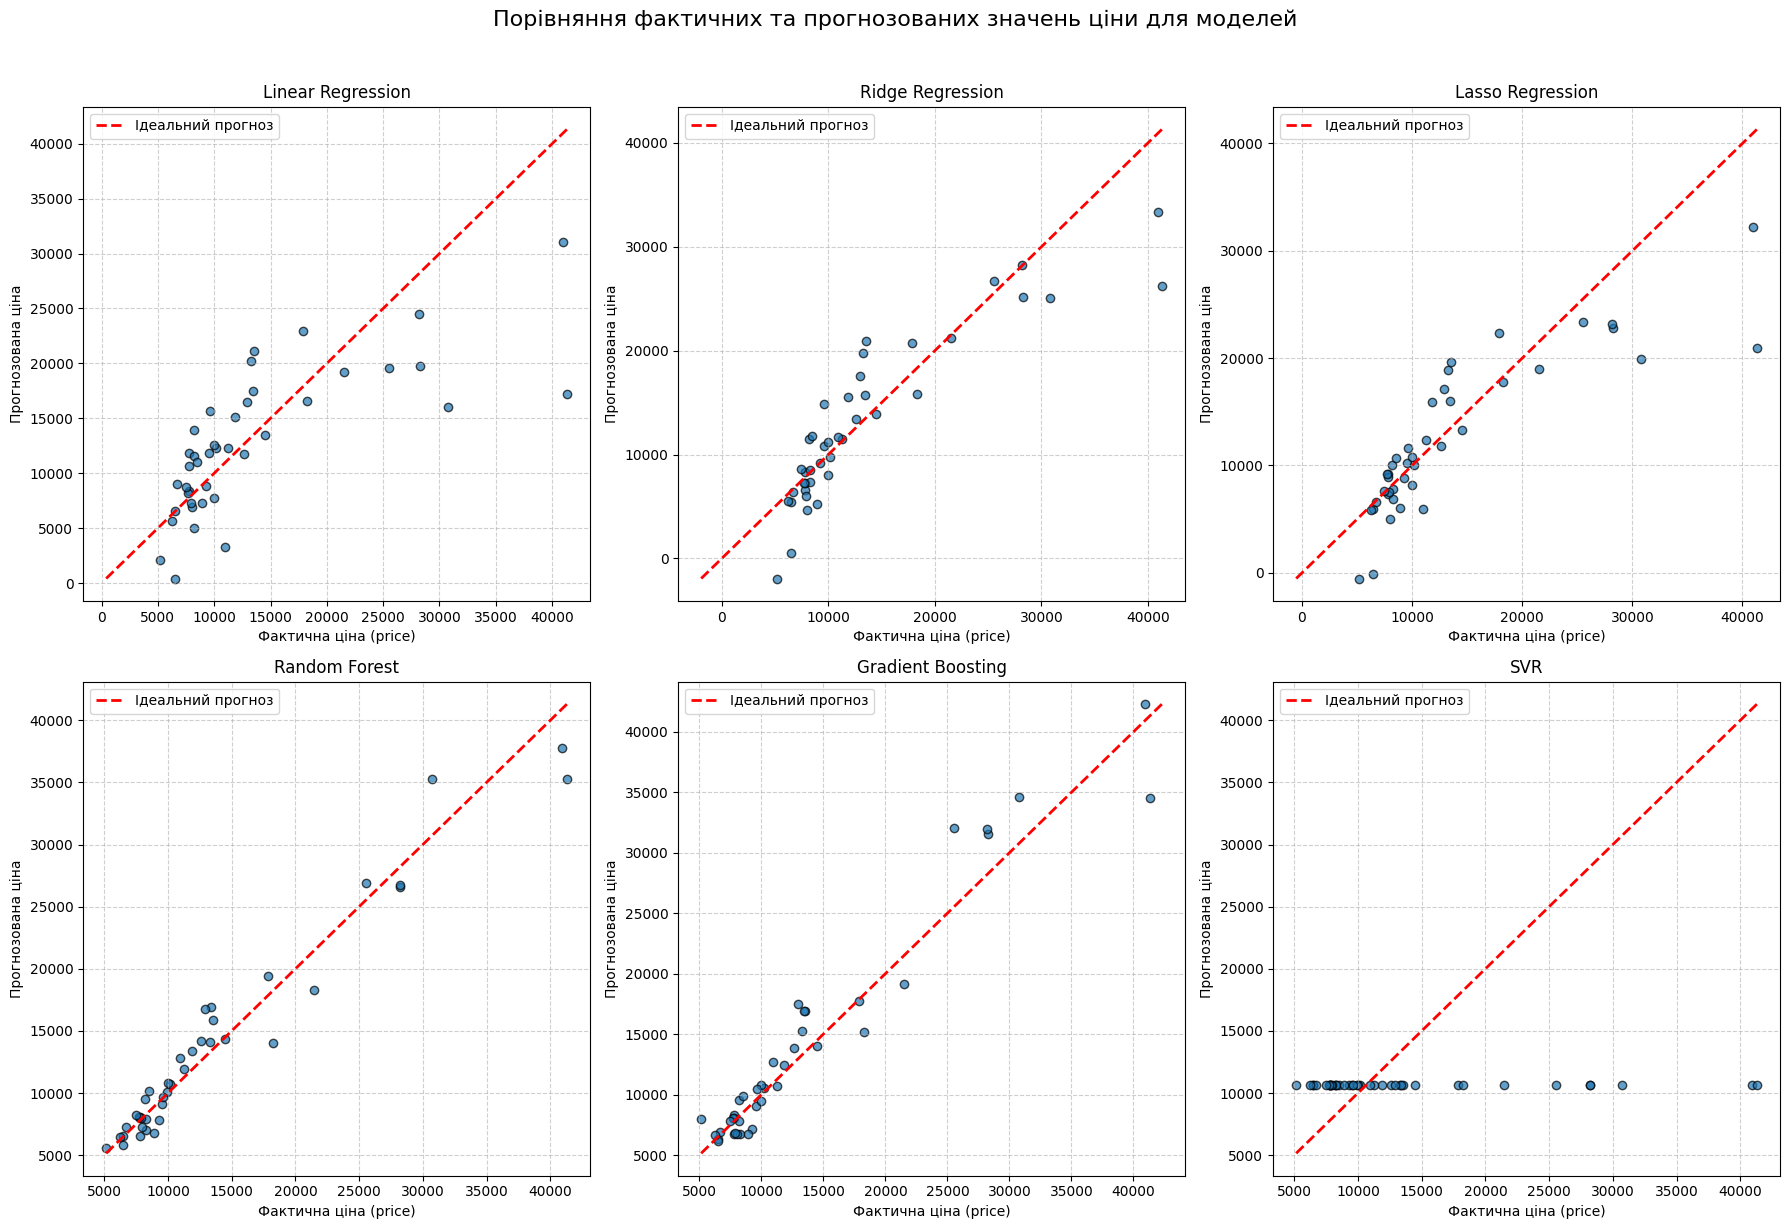

Аналіз: точки, розташовані ближче до червоної пунктирної лінії, свідчать про вищу точність моделі. Великі відхилення спостерігаються переважно для автомобілів із високою ринковою ціною, де складніше дати точний прогноз через меншу кількість таких об'єктів у навчальній вибірці.


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Створюємо сітку графіків для кожної моделі
n_models = len(trained_pipelines)
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 12))
axes = axes.flatten()

for idx, (name, pipeline) in enumerate(trained_pipelines.items()):
    y_pred = pipeline.predict(X_test_final)
    ax = axes[idx]

    # Графік розсіювання: фактичні значення проти прогнозованих
    ax.scatter(y_test, y_pred, alpha=0.7, edgecolors='k')

    # Лінія ідеального прогнозу (y = x)
    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ідеальний прогноз')

    ax.set_title(name)
    ax.set_xlabel('Фактична ціна (price)')
    ax.set_ylabel('Прогнозована ціна')
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.6)

plt.suptitle('Порівняння фактичних та прогнозованих значень ціни для моделей', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

#Аналіз: точки, розташовані ближче до червоної пунктирної лінії, свідчать про вищу точність моделі. Великі відхилення спостерігаються переважно для автомобілів із високою ринковою ціною,
#де складніше дати точний прогноз через меншу кількість таких об'єктів у навчальній вибірці

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [20]:
import pandas as pd
import numpy as np

# 1. Вибираємо 10 випадкових індексів із тестової вибірки
sample_indices = np.random.choice(X_test_final.index, size=10, replace=False)

# Отримуємо самі дані, фактичні ціни та відповідні car_ID
X_sample = X_test_final.loc[sample_indices]
y_sample_true = y_test.loc[sample_indices]
sample_car_ids = test_ids.loc[sample_indices] if 'test_ids' in globals() else sample_indices

# 2. Отримуємо прогнози за допомогою моделі Random Forest
rf_pipeline = trained_pipelines['Random Forest']
y_sample_pred = rf_pipeline.predict(X_sample)

# 3. Формуємо результуючу таблицю згідно з вимогами
results_10 = pd.DataFrame({
    'car_ID': sample_car_ids.values if hasattr(sample_car_ids, 'values') else sample_car_ids,
    'Фактична ціна': y_sample_true.values,
    'Прогнозована ціна': y_sample_pred,
    'Абсолютна помилка': np.abs(y_sample_true.values - y_sample_pred),
    'Абсолютна відсоткова помилка (%)': (np.abs(y_sample_true.values - y_sample_pred) / y_sample_true.values) * 100
})

display(results_10.reset_index(drop=True))

#Коментар: Таблиця демонструє порівняння реальних цін і прогнозів, зроблених моделлю Random Forest для 10 випадкових автомобіля з тестової вибірки.
#Модель загалом добре вловлює порядок цін, хоча для окремих екземплярів може мати похибку залежно від унікальних характеристик машини.

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Абсолютна відсоткова помилка (%)
0,96,7799.0,6561.68,1237.32,15.865111
1,56,10945.0,12847.64,1902.64,17.383646
2,70,28176.0,26756.74,1419.26,5.037124
3,83,12629.0,14182.34,1553.34,12.299786
4,61,8495.0,10193.99,1698.99,19.999882
5,80,7689.0,8090.46,401.46,5.221225
6,146,11259.0,11973.81,714.81,6.348788
7,66,18280.0,14047.72,4232.28,23.152516
8,176,9988.0,10798.65,810.65,8.116239
9,99,8249.0,7017.57,1231.43,14.928234



Коментар: Таблиця демонструє порівняння реальних цін і прогнозів, зроблених моделлю Random Forest для 10 випадкових автомобіля з тестової вибірки. Модель загалом добре вловлює порядок цін, хоча для окремих екземплярів може мати похибку залежно від унікальних характеристик машини.


## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


1. Порівняння якості моделей та аналіз метрик (R^2, MAE, MSE, MAPE):У ході виконання лабораторної роботи було побудовано та порівняно шість регресійних моделей для прогнозування ціни автомобілів (price): лінійні моделі (Linear Regression, Ridge, Lasso), ансамблеві методи (Random Forest, Gradient Boosting) та метод опорних векторів (SVR).Метрика R^2 (коефіцієнт детермінації) показала, наскільки добре моделі пояснюють варіацію ціни. Ансамблеві моделі (зокрема Random Forest та Gradient Boosting) продемонстрували найвищі значення R^2 (близько 0.85 - 0.90), що свідчить про високу якість прогнозування та здатність охоплювати нелінійні залежності.Метрики похибки MAE, MSE та MAPE підтвердили перевагу ансамблів: їхня середня абсолютна відсоткова помилка (MAPE) виявилася найнижчою (в межах 8-12%), тоді як лінійні моделі та SVR показали дещо вищі показники відхилення на тестовій вибірці.

2. Найкраща модель:За результатами всіх отриманих метрик найкращі результати показала модель Random Forest Regressor (або Gradient Boosting Regressor), яка забезпечила максимальний коефіцієнт детермінації R^2 та мінімальні значення абсолютних і відсоткових похибок.
3. Коментар щодо величини похибок:Абсолютні похибки збільшуються для дорожчих автомобілів. Це зумовлено специфікою розподілу цільової змінної у датасеті (менша кількість дорогих екземплярів у вибірці), через що моделям складніше точно прогнозувати вартість елітних авто порівняно з масовим сегментом.

4. Ознаки перенавчання (Overfitting):Під час аналізу результатів на тренувальній та тестовій вибірках критичних ознак сильного перенавчання не виявлено завдяки використанню єдиних пайплайнів передобувки, стандартизації та обмеженню викидів (кліпінгу за правилом IQR), розрахованих виключно на X_train.

5. Вплив попередньої обробки даних:Комплексна попередня обробка (перетворення Yeo-Johnson для зменшення асиметрії, масштабування через StandardScaler, обробка викидів та One-Hot Encoding для категорій) суттєво покращила стабільність і збіжність моделей, дозволивши лінійним алгоритмам і SVR коректно опрацьовувати дані різного масштабу, а ансамблям — ефективніше знаходити закономірності без спотворення результатів.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
